[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch42_LabCh42_Tiny_RAG.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 42: Retrieval-Augmented Generation** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=42](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=42)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch42 - A tiny RAG, retrieval half first
## Chunk a collection, embed it three ways, search it, and measure how often the right passage comes back

This lab goes with **Chapter 42** of *The Why Book of Deep Learning, Part 2*.

Retrieval-augmented generation has two halves: **find** the passages that bear on a question, then let a
language model **write** an answer from them. This lab builds the first half from nothing and measures it.
The second half needs a large model, which a laptop lab does not have, so the lab stops where the large model
would start: it assembles the prompt, and a small stand-in "reader" points at the sentence that holds the answer.

The collection is written inside the notebook: a made-up gazetteer of 480 towns, six short facts each, bound
into 60 pages. Because the notebook wrote every sentence, it knows which sentence answers which question.
That is the one thing a retrieval experiment cannot do without.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Cut documents into chunks three ways and say what each cut loses | Steps 4 and 12 |
| Build a TF-IDF index by hand and search it with one matrix multiply | Step 5 |
| Measure recall@1, @3, @10 and MRR, split by kind of question | Step 6 |
| Train word vectors and a contrastive encoder, and say why one retrieves and the other does not | Steps 7 and 8 |
| Fuse keyword and vector search, and see a fusion rule fail | Step 10 |
| Train a reranker that reads question and passage together | Step 11 |
| Trade recall for speed with an approximate index | Step 13 |
| Assemble a grounded prompt, and give the system a way to say "I do not know" | Steps 14 and 15 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** about one minute on a laptop CPU. No GPU, no downloads.

> **Honest scale:** this is a miniature. 480 short passages written from templates, a vocabulary of about
> 1,600 words, encoders with about 100,000 weights. A real collection has millions of messy passages and an
> embedding model with hundreds of millions of weights trained on hundreds of millions of pairs. Read the lab
> for **which method fails on which kind of question, and why**. The percentages belong to this toy and to
> nothing else.

---
## Step 1 - Imports and one seed

In [1]:
import os, re, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Write the collection

Each town gets six facts: the country round it, who founded it and when, what it is known for, a yearly
event, a registry code, and (for about half) its nearest neighbour.

Two things are done on purpose, because real text does them too:

* **Only the first sentence names the town.** The others say "It".
* **The same thing can be said in several words.** A timber town may be described with `timber`, `sawmills`,
  `lumber`, `loggers` or `planks`; an autumn event may be in `autumn`, `fall` or `october`. The entry picks
  some of these at random. Later, a question will pick again, and may pick differently.

> **Predict:** an entry is five or six short sentences. About how many words? And how many different words
> (the vocabulary) will 480 entries use: hundreds, thousands, tens of thousands?

In [2]:
HEADS = ("Marrow Bren Tor Vask Hel Dun Kor Sel Ost Pell Ash Wyn Garth Lin Stan Hax Mer Cald Thorn Rook Elm Fen "
         "Ives Quill Bex Crag Holt Nor Pike Wex").split()
TAILS = "wick ford holm by stead mere haven thorpe gate combe ness field bury worth cott dale ley mouth stoke minster".split()
FIRST = "Tovald Ines Maro Petra Jorun Sabel Oskar Lune Edda Corin Hale Brisa Anselm Yrsa Dorin Mabel Ruben Tilde Gerrit Sunna".split()
LAST = "Brenk Voss Arkel Hollin Strand Quist Marlow Dray Fenn Kessel Oram Tulk Varga Wren Yarrow Zell Pask Linde Corbe Hask".split()
JOBS = "physician merchant captain miller priest widow surveyor exile poet blacksmith".split()
SETTLE = "village town hamlet settlement".split()
FOUND_P, FOUND_Q = "founded established settled".split(), "founded established started begun".split()   # passage words, question words
KNOWN_P, KNOWN_Q = "known famous renowned".split(), "known famous noted celebrated".split()
LAND = {
    "lakes": "lakes ponds meres tarns", "mountains": "mountains peaks crags ridges", "marshes": "marshes bogs fens swamps",
    "coast": "cliffs coves beaches dunes", "forests": "forests woods groves thickets", "rivers": "rivers streams brooks waterfalls",
    "moors": "moors heaths downs steppes", "valleys": "valleys glens dales hollows", "islands": "islands reefs atolls skerries",
    "deserts": "deserts sands canyons mesas"}
TRADE = {
    "wood": "timber sawmills lumber loggers planks", "fish": "herring trawlers nets fishermen smokehouses",
    "glass": "glassblowers furnaces bottles lenses mirrors", "wool": "sheep wool looms weavers shepherds",
    "salt": "saltworks brine salt saltpans salters", "wine": "vineyards wine grapes cellars vintners",
    "iron": "forges smiths anvils ironworks foundries", "clay": "kilns potters clay pottery tiles",
    "bees": "hives honey beekeepers wax mead", "boats": "shipyards hulls boatwrights sails masts",
    "paper": "paper printers presses inks bookbinders", "stone": "quarries granite masons marble slate",
    "bread": "mills flour bakers ovens loaves", "horses": "stables horses saddlers farriers paddocks"}
SEASON = {"spring": "spring april may", "summer": "summer june july", "autumn": "autumn fall october", "winter": "winter december january"}
EVENT = {"fair": "fair market bazaar", "race": "race regatta derby", "feast": "feast banquet supper",
         "parade": "parade procession pageant", "music": "concert recital serenade", "fire": "bonfire beacon blaze",
         "dance": "dance ball reel", "contest": "tournament contest championship"}
for table in (LAND, TRADE, SEASON, EVENT):
    for key in table:
        table[key] = table[key].split()

N_TOWNS = 480
pick = lambda seq: seq[rng.integers(len(seq))]

all_names = [h + t for h in HEADS for t in TAILS]                 # 30 x 20 = 600 possible names
rng.shuffle(all_names)
names, spare_names = all_names[:N_TOWNS], all_names[N_TOWNS:]     # 120 names are kept back for Step 15
all_combos = [(a, b, c, d) for a in LAND for b in TRADE for c in SEASON for d in EVENT]
rng.shuffle(all_combos)
combos, spare_combos = all_combos[:N_TOWNS], all_combos[N_TOWNS:]  # no two towns share land + trade + season + event
codes = set()
while len(codes) < N_TOWNS:
    codes.add(pick(list("ABCDEFGHJKLMNPRSTUVWXYZ")) + pick(list("ABCDEFGHJKLMNPRSTUVWXYZ")) + "-" + str(rng.integers(1000, 9999)))
codes = sorted(codes)
rng.shuffle(codes)

towns = []
for i in range(N_TOWNS):
    land, trade, season, event = combos[i]
    towns.append(dict(name=names[i], land=land, trade=trade, season=season, event=event, code=codes[i],
                      year=int(rng.integers(1200, 1900)), job=pick(JOBS), founder=pick(FIRST) + " " + pick(LAST),
                      neighbour=pick(names) if rng.random() < 0.5 else None))


def write_entry(t):
    """The facts about one town, as a list of sentences. Only the first sentence names the town."""
    l1, l2 = rng.choice(LAND[t["land"]], 2, replace=False)
    w1, w2 = rng.choice(TRADE[t["trade"]], 2, replace=False)
    s = [f"{t['name']} is a {pick(SETTLE)} in a land of {l1} and {l2}.",
         f"It was {pick(FOUND_P)} in {t['year']} by the {t['job']} {t['founder']}.",
         f"It is {pick(KNOWN_P)} for its {w1} and its {w2}.",
         f"Every {pick(SEASON[t['season']])} it holds a {pick(EVENT[t['event']])}.",
         f"Its registry code is {t['code']}."]
    if t["neighbour"] and t["neighbour"] != t["name"]:
        s.append(f"The nearest {pick(SETTLE)} is {t['neighbour']}.")
    return s


entries = [write_entry(t) for t in towns]
entry_words = [sum(len(s.split()) for s in e) for e in entries]
print(f"{N_TOWNS} entries, {sum(entry_words):,} words, {np.mean(entry_words):.1f} words per entry on average "
      f"(shortest {min(entry_words)}, longest {max(entry_words)})")
print(f"{len(all_combos):,} possible combinations of land, trade, season and event; each town has its own")
for i in (0, 1):
    print(f"\nentry {i}: " + " ".join(entries[i]))

480 entries, 20,980 words, 43.7 words per entry on average (shortest 41, longest 46)
4,480 possible combinations of land, trade, season and event; each town has its own

entry 0: Holtholm is a hamlet in a land of meres and lakes. It was established in 1407 by the poet Ines Oram. It is known for its lenses and its bottles. Every december it holds a supper. Its registry code is DX-6076. The nearest hamlet is Torstoke.

entry 1: Elmcombe is a settlement in a land of ridges and mountains. It was founded in 1251 by the miller Corin Zell. It is famous for its brine and its saltworks. Every january it holds a recital. Its registry code is LR-2900. The nearest village is Fendale.


---
## Step 3 - Questions whose answers we know

Ten questions per town, of three kinds:

* **name** questions (six per town) name the town and ask for one fact: `Who founded Cragcott?`
  The answer sits in a sentence that does **not** contain the name.
* **describe** questions (three) do not name the town. They describe it, drawing their own words from the
  same word lists the entry drew from: `Which place among the woods is noted for its inks and has a blaze each july?`
  The entry says `thickets and groves`, `inks and paper`, and `summer`.
* **code** questions (one) quote the registry code: `Which place has the registry code JM-7015?`

For every question the notebook records the **gold sentence**: the one that holds the answer.

Then the towns are split: 320 are **training towns** (their questions will train the encoders in Steps 8, 11
and 14) and 160 are **test towns**. Every number in this lab is measured on questions about test towns: towns
whose names and codes no trained model has ever been asked about. All 480 entries go into the index. That is
the real situation: an embedding model is trained once, then asked to index documents it has never seen.

> **Predict:** which kind of question will a keyword search find easiest, and which hardest? Hold on to that.

In [3]:
def write_questions(t):
    """Ten questions about one town: (kind, question, index of the sentence that holds the answer)."""
    n = t["name"]
    q = [("name", f"Who {pick(FOUND_Q)} {n}?", 1),
         ("name", f"In which year was {n} {pick(FOUND_Q)}?", 1),
         ("name", f"What is {n} {pick(KNOWN_Q)} for?", 2),
         ("name", f"Which yearly event takes place in {n}?", 3),
         ("name", f"What is the registry code of {n}?", 4),
         ("name", f"What kind of country lies around {n}?", 0)]
    for _ in range(3):
        q.append(("describe", f"Which place among the {pick(LAND[t['land']])} is {pick(KNOWN_Q)} for its "
                              f"{pick(TRADE[t['trade']])} and has a {pick(EVENT[t['event']])} each {pick(SEASON[t['season']])}?", 0))
    q.append(("code", f"Which place has the registry code {t['code']}?", 0))
    return q


is_test = np.zeros(N_TOWNS, bool)
is_test[rng.choice(N_TOWNS, 160, replace=False)] = True
questions = [dict(kind=kind, text=text, town=i, sent=sent, test=bool(is_test[i]))
             for i, t in enumerate(towns) for kind, text, sent in write_questions(t)]
train_q = [q for q in questions if not q["test"]]
test_q = [q for q in questions if q["test"]]
KINDS = ("name", "code", "describe")
kind_of = np.array([q["kind"] for q in test_q])
print(f"{len(train_q):,} training questions about {int((~is_test).sum())} towns; "
      f"{len(test_q):,} test questions about {int(is_test.sum())} other towns")
print("test questions by kind:", {k: int((kind_of == k).sum()) for k in KINDS})
t0 = test_q[0]["town"]
print(f"\nentry: " + " ".join(entries[t0]))
for q in [q for q in test_q if q["town"] == t0]:
    print(f"  [{q['kind']:8s}] {q['text']}\n{'':13s}gold: {entries[t0][q['sent']]}")

3,200 training questions about 320 towns; 1,600 test questions about 160 other towns
test questions by kind: {'name': 960, 'code': 160, 'describe': 480}

entry: Cragcott is a settlement in a land of thickets and groves. It was founded in 1722 by the captain Sunna Varga. It is famous for its inks and its paper. Every summer it holds a blaze. Its registry code is JM-7015. The nearest settlement is Rookholm.
  [name    ] Who founded Cragcott?
             gold: It was founded in 1722 by the captain Sunna Varga.
  [name    ] In which year was Cragcott founded?
             gold: It was founded in 1722 by the captain Sunna Varga.
  [name    ] What is Cragcott known for?
             gold: It is famous for its inks and its paper.
  [name    ] Which yearly event takes place in Cragcott?
             gold: Every summer it holds a blaze.
  [name    ] What is the registry code of Cragcott?
             gold: Its registry code is JM-7015.
  [name    ] What kind of country lies around Cragcott?
  

---
## Step 4 - Pages, and three ways to cut them

A retrieval system is not handed tidy entries. It is handed **documents**. Ours are 60 pages of 8 entries
each, in shuffled order. Before anything can be searched, each page must be cut into **chunks**.

* `chunk_by_entry()` cuts on structure: one entry, one chunk. (In a real document: headings and paragraphs.)
* `chunk_fixed(size, overlap)` cuts blindly: a window of `size` words, moved along by `size - overlap` words.

A chunk is `(page, first word, last word + 1)`. A chunk **holds the answer** to a question if the whole gold
sentence lies inside it. That is the test every recall number in this lab is built on.

The lab runs on entry chunks until Step 12, which goes back and tries the blind cuts.

> **Predict:** cut the 60 pages into windows of 40 words with no overlap. An entry is about 43 words. For the
> question `Who founded Cragcott?`, the name is in one sentence and the answer in the next. How often will the
> two land in the same chunk: nearly always, about half the time, rarely?

In [4]:
PER_PAGE = 8
order = rng.permutation(N_TOWNS)                       # the order in which the towns are printed
pages, gold_span, entry_span = [], {}, {}
for p in range(N_TOWNS // PER_PAGE):
    words = []
    for i in order[p * PER_PAGE:(p + 1) * PER_PAGE]:
        first = len(words)
        for k, sentence in enumerate(entries[i]):
            a = len(words)
            words += sentence.split()
            gold_span[(int(i), k)] = (p, a, len(words))
        entry_span[int(i)] = (p, first, len(words))
    pages.append(words)


def chunk_by_entry():
    return [entry_span[int(i)] for i in order]


def chunk_fixed(size, overlap=0):
    out = []
    for p, words in enumerate(pages):
        a = 0
        while True:
            out.append((p, a, min(a + size, len(words))))
            if a + size >= len(words):
                break
            a += size - overlap
    return out


def chunk_text(c):
    return " ".join(pages[c[0]][c[1]:c[2]])


def holds_answer(c, q):
    p, a, b = gold_span[(q["town"], q["sent"])]
    return c[0] == p and c[1] <= a and b <= c[2]


chunks = chunk_by_entry()
chunk_of_town = {int(i): j for j, i in enumerate(order)}
print(f"{len(pages)} pages, {np.mean([len(p) for p in pages]):.0f} words per page on average")
print(f"cut by entry        : {len(chunks)} chunks")
for size, overlap in ((40, 0), (40, 20), (10, 0), (320, 0)):
    cs = chunk_fixed(size, overlap)
    together = np.mean([any(holds_answer(c, q) and c[1] <= entry_span[q["town"]][1] for c in cs)
                        for q in test_q if q["kind"] == "name" and q["sent"] > 0])
    print(f"windows of {size:3d}, overlap {overlap:2d}: {len(cs):4d} chunks; "
          f"name and answer in one chunk for {together:.0%} of name questions")
print("\na 40-word window:", chunk_text(chunk_fixed(40)[1]))

60 pages, 350 words per page on average
cut by entry        : 480 chunks
windows of  40, overlap  0:  543 chunks; name and answer in one chunk for 42% of name questions


windows of  40, overlap 20: 1017 chunks; name and answer in one chunk for 61% of name questions


windows of  10, overlap  0: 2125 chunks; name and answer in one chunk for 0% of name questions
windows of 320, overlap  0:  120 chunks; name and answer in one chunk for 88% of name questions

a 40-word window: BE-3833. Haxcombe is a settlement in a land of glens and hollows. It was established in 1442 by the merchant Edda Fenn. It is famous for its mead and its hives. Every winter it holds a beacon. Its registry code


### Why we see this

A blind 40-word window does not line up with a 43-word entry. For more than half of the name questions the
town's name is in one chunk and the fact about it is in the next, where it reads "It was founded in ..."
with nothing to say what "It" is. At 10 words the two are never together. Overlap helps, bigger windows help
more, and cutting on the entry boundaries makes the problem vanish. Step 12 measures what each cut does to search.

---
## Step 5 - Keywords: a TF-IDF index by hand

The oldest embedding of a text is a **bag of words**: one number per vocabulary word, counting how often it
appears. Common words are then turned down and rare words up by multiplying each count by the word's
**IDF**, `ln((1 + chunks) / (1 + chunks containing the word)) + 1`. Each row is scaled to length 1.

The index is then one matrix, shape `(chunks, V)`. A question becomes a row of the same kind, shape `(V,)`.
Because every row has length 1, the cosine similarity of the question with **every** chunk is a single
matrix multiply: `(questions, V) @ (V, chunks)`.

> **Predict:** the vocabulary is built from the pages and the training questions. Which word in
> `Who founded Cragcott?` will carry the most weight? And which of these has the highest IDF: `its`, `timber`, a registry code?

In [5]:
def tok(text):
    """Lowercase words and codes. 'JM-7015' stays one token."""
    return re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", text.lower())


vocab = sorted({w for p in pages for w in tok(" ".join(p))} | {w for q in train_q for w in tok(q["text"])})
word_id = {w: i + 2 for i, w in enumerate(vocab)}      # id 0 = padding, id 1 = a word never seen
V = len(vocab) + 2
ids_of = lambda tokens: [word_id.get(w, 1) for w in tokens]


def bag(token_lists):
    """Count matrix (texts, V). Padding and unknown words are not counted."""
    M = np.zeros((len(token_lists), V), np.float32)
    for r, tokens in enumerate(token_lists):
        for i in ids_of(tokens):
            if i > 1:
                M[r, i] += 1
    return M


def unit_rows(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)


def tfidf_index(chunk_tokens):
    counts = bag(chunk_tokens)
    idf = (np.log((1 + len(chunk_tokens)) / (1 + (counts > 0).sum(0))) + 1).astype(np.float32)
    return unit_rows(counts * idf), idf


def tfidf_queries(qs, idf):
    return unit_rows(bag([tok(q["text"]) for q in qs]) * idf)


chunk_tok = [tok(chunk_text(c)) for c in chunks]
test_tok = [tok(q["text"]) for q in test_q]
X_tfidf, idf = tfidf_index(chunk_tok)
t0 = time.time()
S_tfidf = tfidf_queries(test_q, idf) @ X_tfidf.T          # every test question against every chunk
print(f"V = {V:,} (pages and training questions, plus padding and unknown)")
print(f"index {X_tfidf.shape}, {np.mean(X_tfidf > 0):.1%} of it non-zero; "
      f"{S_tfidf.shape[0]:,} questions x {S_tfidf.shape[1]} chunks scored in {1000 * (time.time() - t0):.0f} ms")
print("IDF:", {w: round(float(idf[word_id[w]]), 2) for w in ("its", "is", "timber", "founded", towns[0]["code"].lower())})


def show(q, scores, k=3):
    print(f"\nQ ({q['kind']}): {q['text']}")
    for r, j in enumerate(np.argsort(-scores)[:k]):
        print(f"  {r + 1}. {scores[j]:.3f} {'GOLD' if holds_answer(chunks[j], q) else '    '} {chunk_text(chunks[j])[:88]}...")


for n in (0, 6, 9):
    show(test_q[n], S_tfidf[n])

V = 1,549 (pages and training questions, plus padding and unknown)
index (480, 1549), 2.1% of it non-zero; 1,600 questions x 480 chunks scored in 36 ms
IDF: {'its': 1.0, 'is': 1.0, 'timber': 4.78, 'founded': 2.06, 'dx-6076': 6.48}

Q (name): Who founded Cragcott?
  1. 0.207 GOLD Cragcott is a settlement in a land of thickets and groves. It was founded in 1722 by the...
  2. 0.183      Wexness is a settlement in a land of beaches and dunes. It was established in 1599 by th...
  3. 0.180      Dunwick is a hamlet in a land of forests and thickets. It was settled in 1778 by the poe...

Q (describe): Which place among the woods is noted for its inks and has a blaze each july?
  1. 0.145      Vaskford is a settlement in a land of valleys and glens. It was founded in 1490 by the p...
  2. 0.140 GOLD Cragcott is a settlement in a land of thickets and groves. It was founded in 1722 by the...
  3. 0.138      Marrowbury is a settlement in a land of peaks and ridges. It was established in 1815 by 

### Why we see this

Three questions, three behaviours. The name question and the code question each carry one very rare token,
and a rare token that matches is nearly decisive. The describe question has no such token. It scores only on
the words it happens to share with the entry, and it shares them with many entries.

---
## Step 6 - Measure it: recall@k and MRR

One question proves nothing. **recall@k** is the fraction of questions for which a chunk holding the answer
is among the top k. **MRR** (mean reciprocal rank) averages `1 / rank of the first such chunk`, so it rewards
putting the right chunk first and not only somewhere in the list.

`evaluate` reports both, split by kind of question. Every later step calls it.

> **Predict:** recall@1 and recall@10 of keyword search for each of the three kinds. You made the ranking in Step 3.
> Now put numbers on it.

In [6]:
def gold_ranks(scores, qs, cs):
    """Rank (1 = best) of the first chunk that holds the answer, for each question; a large number if none in the top 50."""
    top = np.argsort(-scores, axis=1)[:, :50]
    ranks = np.full(len(qs), 10 ** 6)
    for n, q in enumerate(qs):
        for r, j in enumerate(top[n]):
            if holds_answer(cs[j], q):
                ranks[n] = r + 1
                break
    return ranks


results = {}


def evaluate(label, scores, qs=None, cs=None, quiet=False):
    qs, cs = qs or test_q, cs or chunks
    ranks = gold_ranks(scores, qs, cs)
    kinds = np.array([q["kind"] for q in qs])
    row = {}
    for kind in KINDS + ("all",):
        r = ranks[kinds == kind] if kind != "all" else ranks
        row[kind] = [float(np.mean(r <= k)) for k in (1, 3, 10)] + [float(np.mean(1.0 / r))]
    results[label] = row
    if not quiet:
        print(f"{label:26s}" + "".join(f" | {kind:8s}" + " ".join(f"{v:6.1%}" for v in row[kind][:3]) for kind in KINDS + ("all",))
              + f" | MRR {row['all'][3]:.3f}")
    return ranks


print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
ranks_tfidf = evaluate("keywords (TF-IDF)", S_tfidf)

# why are some name questions missed at rank 1?
missed = np.where((kind_of == "name") & (ranks_tfidf > 1))[0]
show(test_q[missed[0]], S_tfidf[missed[0]])
mentions = [towns[test_q[n]["town"]]["name"] in chunk_text(chunks[int(np.argmax(S_tfidf[n]))]) for n in missed]
print(f"\n{len(missed)} name questions are missed at rank 1. In {sum(mentions)} of them the chunk at rank 1 is another town's entry "
      f"that names this town as its nearest neighbour.")

# on describe questions: how many distinguishing words (IDF above 3) does the question share with its own entry?
shared = np.array([len({w for w in set(test_tok[n]) & set(chunk_tok[chunk_of_town[q["town"]]]) if idf[word_id[w]] > 3})
                   for n, q in enumerate(test_q)])
print("\ndescribe questions, by the number of distinguishing words the question shares with its entry:")
for m in sorted(set(shared[kind_of == "describe"])):
    sel = (kind_of == "describe") & (shared == m)
    print(f"  {m} shared: {sel.sum():3d} questions, recall@1 {np.mean(ranks_tfidf[sel] <= 1):6.1%}, recall@10 {np.mean(ranks_tfidf[sel] <= 10):6.1%}")

recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10
keywords (TF-IDF)          | name     87.5%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 21.2%  36.9%  52.3% | all      68.9%  81.0%  85.7% | MRR 0.757

Q (name): What is Cragcott known for?
  1. 0.231      Wexness is a settlement in a land of beaches and dunes. It was established in 1599 by th...
  2. 0.209 GOLD Cragcott is a settlement in a land of thickets and groves. It was founded in 1722 by the...
  3. 0.204      Dunwick is a hamlet in a land of forests and thickets. It was settled in 1778 by the poe...

120 name questions are missed at rank 1. In 120 of them the chunk at rank 1 is another town's entry that names this town as its nearest neighbour.

describe questions, by the number of distinguishing words the question shares with its entry:
  0 shared:  69 questions, recall@1   0.0%, recall@10   0.0%
  1 shared: 165 que

### Why we see this

Keyword search is close to perfect when the question quotes a rare string. Its misses on name questions have
one cause: the name also appears in a **neighbour's** entry ("The nearest town is ..."), and that entry can
outscore the right one. By rank 3 the right entry is almost always there.

On describe questions the recall follows the number of distinguishing words the question happens to share
with its entry. Share none or one, and the method is guessing. Keyword search does not know that `lumber`
and `timber` are about the same thing. To it they are two unrelated columns of the matrix.

---
## Step 7 - Word vectors learnt from the collection, averaged

Chapter 18 fixed exactly this: give each word a dense vector, learnt so that words used in similar
surroundings get similar vectors. Here is word2vec's skip-gram with negative sampling in a dozen lines of
Keras: for a word and a neighbour within 4 words, push the dot product of their vectors up; for the word and
a random word, push it down. It is trained on the 480 entries and nothing else: no questions, no labels.

The embedding of a chunk (or a question) is then the **average** of its word vectors, scaled to length 1:
shape `(32,)`, whatever the length of the text.

> **Predict:** look at what is nearest to `timber` after training. Then: will averaged word vectors beat keyword search on
> describe questions? On name questions?

In [7]:
def skipgram_pairs(sequences, window=4, negatives=4):
    centre, context = [], []
    for s in sequences:
        for i, w in enumerate(s):
            for j in range(max(0, i - window), min(len(s), i + window + 1)):
                if j != i:
                    centre.append(w)
                    context.append(s[j])
    centre, context = np.array(centre), np.array(context)
    n = len(centre)
    return (np.concatenate([centre, np.repeat(centre, negatives)]),
            np.concatenate([context, rng.integers(2, V, size=n * negatives)]),
            np.concatenate([np.ones(n), np.zeros(n * negatives)]).astype(np.float32))


D_WORD = 32
t0 = time.time()
centre, context, label = skipgram_pairs([ids_of(t) for t in chunk_tok])
centre_in, context_in = layers.Input(shape=(), dtype="int32"), layers.Input(shape=(), dtype="int32")
word_table = layers.Embedding(V, D_WORD, name="word_vectors")
context_table = layers.Embedding(V, D_WORD, name="context_vectors")
w2v = keras.Model([centre_in, context_in], layers.Dot(axes=1)([word_table(centre_in), context_table(context_in)]))
assert w2v.count_params() == 2 * V * D_WORD
w2v.compile(keras.optimizers.Adam(0.01), loss=keras.losses.BinaryCrossentropy(from_logits=True))
w2v.fit([centre, context], label, batch_size=2048, epochs=8, verbose=0)
W_word = word_table.get_weights()[0]
print(f"skip-gram: {len(label):,} training pairs, {w2v.count_params():,} parameters (2 x {V} x {D_WORD}), {time.time() - t0:.0f} s")


def nearest_words(word, table, k=6):
    U = unit_rows(table)
    return [vocab[i - 2] for i in np.argsort(-(U @ U[word_id[word]])) if i > 1 and vocab[i - 2] != word][:k]


for w in ("timber", "lakes", "fall", "regatta"):
    print(f"  nearest to {w:8s}: {', '.join(nearest_words(w, W_word, 4))}")


def mean_vectors(token_lists, table):
    """Average the word vectors of each text, then scale to length 1. Shape (texts, d)."""
    out = np.zeros((len(token_lists), table.shape[1]), np.float32)
    for r, tokens in enumerate(token_lists):
        ids = [i for i in ids_of(tokens) if i > 1]
        if ids:
            out[r] = table[ids].mean(0)
    return unit_rows(out)


X_word = mean_vectors(chunk_tok, W_word)
S_word = mean_vectors(test_tok, W_word) @ X_word.T
print(f"\nindex {X_word.shape}: {X_word.size * 4 / 1e3:.0f} kB as float32, against {X_tfidf.size * 4 / 1e6:.1f} MB for the dense TF-IDF matrix")
print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
evaluate("keywords (TF-IDF)", S_tfidf)
ranks_word = evaluate("averaged word vectors", S_word)
off = S_word[np.arange(len(test_q)), [chunk_of_town[q["town"]] for q in test_q]]
print(f"\ncosine of a question with its own entry: {off.mean():.3f} on average; with all entries: {S_word.mean():.3f}")

skip-gram: 791,200 training pairs, 99,136 parameters (2 x 1549 x 32), 8 s
  nearest to timber  : planks, sawmills, loggers, lumber
  nearest to lakes   : tarns, meres, ponds, mesas
  nearest to fall    : june, december, july, spring
  nearest to regatta : market, recital, fair, derby

index (480, 32): 61 kB as float32, against 3.0 MB for the dense TF-IDF matrix
recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10
keywords (TF-IDF)          | name     87.5%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 21.2%  36.9%  52.3% | all      68.9%  81.0%  85.7% | MRR 0.757
averaged word vectors      | name      0.7%   1.8%   5.1% | code      1.9%   2.5%   5.0% | describe 10.4%  18.8%  36.2% | all       3.8%   6.9%  14.4% | MRR 0.071

cosine of a question with its own entry: 0.821 on average; with all entries: 0.813


### Why we see this

The word vectors did learn something. The four nearest words to `timber` are the four other timber words.
But look at `fall` and `regatta`: their neighbours are other times of year and other events, **any** of them.
As a search engine the average is worse than keywords on **every** kind of question. Three reasons, all of
them true of real word vectors too:

1. **Similar surroundings is not the same as same meaning.** `fall` and `june` both follow "Every", so
   skip-gram pulls them together. The vectors encode "is a time of year" more strongly than "is autumn",
   and a question about a fall fair needs the second.
2. **An average gives every word one vote.** An entry has about 44 words, of which six or seven distinguish
   it. `is`, `a`, `its`, `the` vote as loudly as `timber`. Every chunk's average ends up near every other's:
   look at the two cosines printed last.
3. **Rare words are barely trained.** A town's name appears once or twice in the whole collection. Its vector
   hardly moved from its random start, so the name that made keyword search easy contributes nothing here.

---
## Step 8 - An encoder trained for the job

The fix is not a bigger architecture. It is a different **training signal**. Keep the same design (a table
of word vectors, averaged, scaled to length 1) but train it on what retrieval needs: a question's vector
should be close to the vector of the passage that answers it, and far from the vectors of other passages.

That is a **contrastive** loss (Chapter 6 named it; Chapter 48 owns it). Take a batch of 64 matched pairs,
compute all 64 x 64 cosines, divide by a temperature, and ask the softmax over each row to pick the diagonal:
each question must pick its own passage out of 64. The other 63 passages are free negatives.

Both texts go through the **same** encoder (a two-tower model with tied towers, also called a bi-encoder,
as in most sentence-embedding models). Shapes: ids `(batch, words)` -> vectors `(batch, words, 64)` ->
average `(batch, 64)`. Each word starts as a random vector of length about 1.

> **Predict:** the parameter count (one table, V x 64, and nothing else). Then: the encoder never sees a test
> town's name during training. What will it do with `Who founded <a name it never trained on>?`

In [8]:
class MaskedMean(layers.Layer):
    """(batch, words, d) and ids (batch, words) -> (batch, d): the average over real words, scaled to length 1."""

    def call(self, vectors, ids):
        ops = keras.ops
        mask = ops.cast(ids > 0, "float32")[..., None]
        mean = ops.sum(vectors * mask, axis=1) / ops.maximum(ops.sum(mask, axis=1), 1.0)
        return mean / ops.sqrt(ops.sum(mean * mean, axis=-1, keepdims=True) + 1e-9)


def build_encoder(d=64, name="encoder"):
    ids = layers.Input(shape=(None,), dtype="int32", name="ids")
    table = layers.Embedding(V, d, embeddings_initializer=keras.initializers.RandomNormal(stddev=d ** -0.5), name="table")
    return keras.Model(ids, MaskedMean(name="mean")(table(ids), ids), name=name)


def pad(token_lists, length=None):
    length = length or max(len(t) for t in token_lists)
    out = np.zeros((len(token_lists), length), np.int32)
    for r, tokens in enumerate(token_lists):
        ids = ids_of(tokens)[:length]
        out[r, :len(ids)] = ids
    return out


def train_contrastive(model, sample_batch, steps, temperature=0.05, lr=3e-3):
    """sample_batch() -> (question ids (B, Lq), passage ids (P, Lp)) with passage row i answering question i (P >= B)."""
    opt = keras.optimizers.Adam(lr)

    @tf.function(reduce_retracing=True)
    def step(q, p):
        with tf.GradientTape() as tape:
            sims = tf.matmul(model(q, training=True), model(p, training=True), transpose_b=True) / temperature
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(tf.range(tf.shape(q)[0]), sims, from_logits=True))
        opt.apply_gradients(zip(tape.gradient(loss, model.trainable_weights), model.trainable_weights))
        return loss

    history = []
    for n in range(steps):
        q, p = sample_batch()
        history.append(float(step(tf.constant(q), tf.constant(p))))
    return history


train_towns = np.where(~is_test)[0]
q_of_town = {int(i): [n for n, q in enumerate(train_q) if q["town"] == i] for i in train_towns}
Q_train = pad([tok(q["text"]) for q in train_q])
P_all = pad(chunk_tok)                                   # every chunk as ids, shape (480, longest chunk)
BATCH = 64


def batch_question_passage():
    """64 different training towns, one question each, with that town's entry."""
    ts = rng.choice(train_towns, BATCH, replace=False)
    return Q_train[[pick(q_of_town[int(i)]) for i in ts]], P_all[[chunk_of_town[int(i)] for i in ts]]


encoder = build_encoder()
assert encoder.count_params() == V * 64
print(f"encoder: {encoder.count_params():,} parameters = {V} x 64. Loss of a blind guess among {BATCH}: ln {BATCH} = {np.log(BATCH):.2f}")
t0 = time.time()
history = train_contrastive(encoder, batch_question_passage, steps=1500)
print(f"trained 1,500 steps in {time.time() - t0:.0f} s; loss {np.mean(history[:10]):.2f} at the start, {np.mean(history[-100:]):.3f} at the end")

Q_test = pad(test_tok)
print(f"questions as ids {Q_test.shape}, chunks as ids {P_all.shape}")
X_enc = encoder.predict(P_all, batch_size=256, verbose=0)
S_enc = encoder.predict(Q_test, batch_size=256, verbose=0) @ X_enc.T
print(f"index {X_enc.shape}\n")
print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
evaluate("keywords (TF-IDF)", S_tfidf)
evaluate("averaged word vectors", S_word)
ranks_enc = evaluate("contrastive encoder", S_enc)

W_enc = encoder.get_layer("table").get_weights()[0]
length = lambda words: float(np.mean([np.linalg.norm(W_enc[word_id[w]]) for w in words]))
print("\nlength of the word vectors after training (every word started near 1.0):")
print(f"  filler (is, a, its, the, in, of, and)        : {length('is a its the in of and'.split()):.2f}")
print(f"  trade, land, season and event words          : {length([w for t in (TRADE, LAND, SEASON, EVENT) for ws in t.values() for w in ws]):.2f}")
print(f"  names of training towns                      : {length([towns[i]['name'].lower() for i in train_towns]):.2f}")
print(f"  names of test towns (never in a training pair): {length([towns[i]['name'].lower() for i in np.where(is_test)[0]]):.2f}")
print("nearest words in the encoder's table:")
for w in ("timber", "lakes", "fall", "regatta"):
    print(f"  nearest to {w:8s}: {', '.join(nearest_words(w, W_enc, 4))}")

encoder: 99,136 parameters = 1549 x 64. Loss of a blind guess among 64: ln 64 = 4.16


trained 1,500 steps in 3 s; loss 3.69 at the start, 0.002 at the end
questions as ids (1600, 16), chunks as ids (480, 46)
index (480, 64)

recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10


keywords (TF-IDF)          | name     87.5%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 21.2%  36.9%  52.3% | all      68.9%  81.0%  85.7% | MRR 0.757
averaged word vectors      | name      0.7%   1.8%   5.1% | code      1.9%   2.5%   5.0% | describe 10.4%  18.8%  36.2% | all       3.8%   6.9%  14.4% | MRR 0.071
contrastive encoder        | name     10.5%  20.2%  35.5% | code     13.8%  30.6%  43.1% | describe 64.6%  88.1%  98.1% | all      27.1%  41.6%  55.1% | MRR 0.370

length of the word vectors after training (every word started near 1.0):
  filler (is, a, its, the, in, of, and)        : 0.82
  trade, land, season and event words          : 1.10
  names of training towns                      : 1.23
  names of test towns (never in a training pair): 1.01
nearest words in the encoder's table:
  nearest to timber  : loggers, sawmills, lumber, fm-2281
  nearest to lakes   : ponds, meres, tarns, 1739
  nearest to fall    : autumn, october, 1321, 1513
  nearest to regatta : d

### Why we see this

Same architecture as Step 7, to the last detail: a table, an average. Only the training changed, and on
describe questions recall@1 is about six times higher. Look at what the encoder did to its table. It
turned the filler words down and the words that tell towns apart up: it learnt something like IDF by itself,
because the loss rewarded nothing else. And `fall` now sits next to `autumn` and `october`, not next to
`june`: a question about a fall fair must be kept away from June fairs, so the loss pulled them apart.

On name and code questions it is poor. A test town's name was never in a training pair, so its vector is
still the random one it started with. The same word in question and entry still matches itself (that is why
the recall is not zero), but one unremarkable vector in an average of 44 is easily outvoted. This is a
miniature of a real weakness: an embedding compresses a passage to a few hundred numbers, and exact
strings (names, part numbers, error codes) are what the compression loses first. Real models see names as
subword pieces and do better than ours. They still do not match a keyword index on exact strings.

---
## Step 9 - The scoreboard so far

> **Predict:** before you look at the picture, which method would you ship if you could have only one? Then
> look at recall@10 and ask what a second method could add.

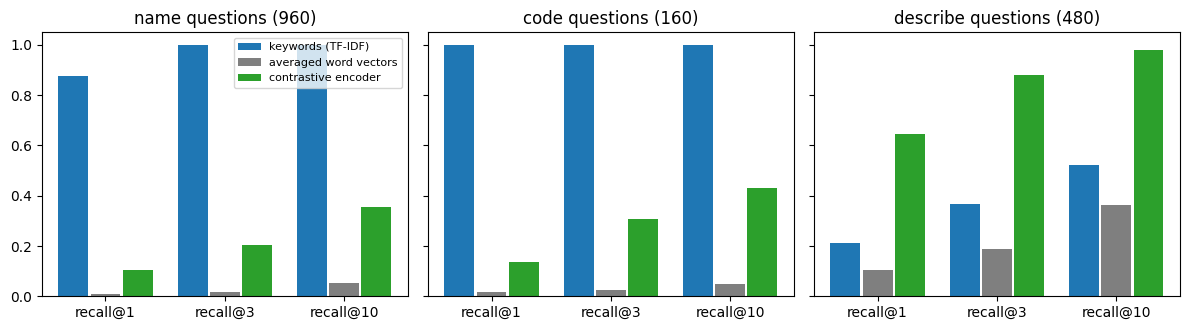

top 10 holds the answer:
  for keywords only   :  44.4% of test questions
  for the encoder only:  13.8%
  for both            :  41.3%
  for neither         :   0.6%
  for at least one    :  99.4%   <- what a perfect combination could reach


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
methods = [("keywords (TF-IDF)", "tab:blue"), ("averaged word vectors", "tab:gray"), ("contrastive encoder", "tab:green")]
for ax, kind in zip(axes, KINDS):
    for m, (label, colour) in enumerate(methods):
        vals = results[label][kind][:3]
        ax.bar(np.arange(3) + (m - 1) * 0.27, vals, 0.25, color=colour, label=label)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["recall@1", "recall@3", "recall@10"])
    ax.set_title(f"{kind} questions ({(kind_of == kind).sum()})")
    ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

both = (ranks_tfidf <= 10) & (ranks_enc <= 10)
print("top 10 holds the answer:")
print(f"  for keywords only   : {np.mean((ranks_tfidf <= 10) & ~(ranks_enc <= 10)):6.1%} of test questions")
print(f"  for the encoder only: {np.mean(~(ranks_tfidf <= 10) & (ranks_enc <= 10)):6.1%}")
print(f"  for both            : {np.mean(both):6.1%}")
print(f"  for neither         : {np.mean(~(ranks_tfidf <= 10) & ~(ranks_enc <= 10)):6.1%}")
print(f"  for at least one    : {np.mean((ranks_tfidf <= 10) | (ranks_enc <= 10)):6.1%}   <- what a perfect combination could reach")

### Why we see this

The two methods fail on **different questions**. Keywords need a shared rare word; the encoder needs words
it was trained on. That is the best possible news: two imperfect searches whose mistakes do not overlap are
worth combining.

---
## Step 10 - Hybrid search: fuse the two lists

Two common ways to combine a keyword list with a vector list:

* **Score fusion.** Put the two scores on a common scale (here: for each question, subtract the mean over all
  chunks and divide by the standard deviation), then add them.
* **Reciprocal rank fusion (RRF).** Forget the scores. Give each chunk `1 / (60 + rank)` from each list and add.
  RRF needs no scaling and is a popular default.

> **Predict:** on a name question, the keyword list has the right entry at rank 1 or 2 and the encoder has
> it at rank 200. Under RRF, can a chunk that is rank 8 in **both** lists beat it? Work it out:
> `1/61 + 1/260` against `2/68`.

In [10]:
def zscore(S):
    return (S - S.mean(1, keepdims=True)) / S.std(1, keepdims=True)


def rrf(score_lists, k=60):
    total = 0.0
    for S in score_lists:
        rank = np.argsort(np.argsort(-S, axis=1), axis=1) + 1
        total = total + 1.0 / (k + rank)
    return total


S_hybrid = zscore(S_tfidf) + zscore(S_enc)
S_rrf = rrf([S_tfidf, S_enc])
print(f"1/61 + 1/260 = {1 / 61 + 1 / 260:.4f}   2/68 = {2 / 68:.4f}\n")
print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
evaluate("keywords (TF-IDF)", S_tfidf)
evaluate("contrastive encoder", S_enc)
ranks_hybrid = evaluate("hybrid, score fusion", S_hybrid)
ranks_rrf = evaluate("hybrid, RRF", S_rrf)
print(f"\nrecall@20 of score fusion: {np.mean(ranks_hybrid <= 20):.1%}   (the candidates the next step will rerank)")
n = int(np.where((kind_of == "name") & (ranks_tfidf == 1) & (ranks_rrf > 3))[0][0])
print(f"\none name question: '{test_q[n]['text']}'  keywords rank {ranks_tfidf[n]}, encoder rank {ranks_enc[n] if ranks_enc[n] <= 50 else 'beyond 50'}, "
      f"RRF rank {ranks_rrf[n]}, score fusion rank {ranks_hybrid[n]}")

1/61 + 1/260 = 0.0202   2/68 = 0.0294

recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10
keywords (TF-IDF)          | name     87.5%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 21.2%  36.9%  52.3% | all      68.9%  81.0%  85.7% | MRR 0.757
contrastive encoder        | name     10.5%  20.2%  35.5% | code     13.8%  30.6%  43.1% | describe 64.6%  88.1%  98.1% | all      27.1%  41.6%  55.1% | MRR 0.370
hybrid, score fusion       | name     75.0%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 37.3%  55.6%  80.2% | all      66.2%  86.6%  94.1% | MRR 0.771
hybrid, RRF                | name     45.2%  74.3%  93.9% | code     63.1%  83.1%  93.8% | describe 39.2%  54.8%  75.6% | all      45.2%  69.3%  88.4% | MRR 0.599

recall@20 of score fusion: 95.9%   (the candidates the next step will rerank)

one name question: 'Who founded Cragcott?'  keywords rank 1, encoder rank beyo

### Why we see this

Score fusion finds the answer in its top 10 more often than either method alone, which is what a hybrid is
for. At rank 1 it is a compromise: on each kind of question it lands between its two parents.

RRF does badly here, and the reason is worth keeping. RRF throws away how **sure** each list is. On a name
question the keyword search has one overwhelming score and the encoder has 480 nearly equal ones; RRF reads
both as a plain ranking and lets the encoder's noise drag the right entry down. Score fusion keeps the
keyword search's confidence. RRF works well when both lists are decent on most questions, the usual case
with production retrievers. Here one list is nearly blind to half the questions, and rank fusion
cannot tell.

---
## Step 11 - A reranker that reads question and passage together

The encoder must squeeze a passage into 64 numbers **before** it knows the question. A **reranker** (a
cross-encoder) is allowed to look at the two together. That is too slow to do for every chunk, so it is run
on a short list: here the top 20 of the hybrid.

A real reranker is a transformer that reads `question [SEP] passage`. Ours is a miniature with the one
property that matters: it compares **word by word**. It borrows the Step 8 encoder's word vectors and
**freezes** them, so it knows no word the encoder did not. For each question word it looks along the
passage and records four things:

1. the best cosine with any passage word,
2. whether the exact word is there,
3. where it is (1 for the passage's first word, falling towards 0 at its end; 0 if absent),
4. the word's IDF.

A two-layer network turns the four into a score per question word, and the scores are added. Shapes:
`(batch, 16 question words)` and `(batch, 46 passage words)` -> similarities `(batch, 16, 46)` -> features
`(batch, 16, 4)` -> one score `(batch,)`.

It is trained on the training towns with **hard negatives**: for each question, the right entry and four
wrong entries taken from the hybrid's own top 20, the mistakes the first stage really makes.

> **Predict:** the trainable parameters: Dense(16) on 4 features, then Dense(1). With so few, and with word
> vectors the encoder already had, can it beat the encoder? On which kind of question, and why?

reranker: 97 trainable parameters = (4 x 16 + 16) + (16 + 1); frozen: the encoder's 1549 x 64 table and an IDF column


trained 600 steps in 2 s; loss 1.26 at the start (ln 5 = 1.61), 0.055 at the end


reranked 1,600 x 20 candidates in 0.5 s

recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10
keywords (TF-IDF)          | name     87.5%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 21.2%  36.9%  52.3% | all      68.9%  81.0%  85.7% | MRR 0.757
contrastive encoder        | name     10.5%  20.2%  35.5% | code     13.8%  30.6%  43.1% | describe 64.6%  88.1%  98.1% | all      27.1%  41.6%  55.1% | MRR 0.370
hybrid, score fusion       | name     75.0%  99.9% 100.0% | code    100.0% 100.0% 100.0% | describe 37.3%  55.6%  80.2% | all      66.2%  86.6%  94.1% | MRR 0.771
hybrid top 20 + reranker   | name     99.8% 100.0% 100.0% | code    100.0% 100.0% 100.0% | describe 76.9%  84.8%  86.2% | all      92.9%  95.4%  95.9% | MRR 0.941

ceiling: the reranker can only reorder what it is given. The hybrid's recall@20 was 95.9%; after reranking, recall@20 is 95.9%
  name    : hybrid recall@20

recall at 1, 3, 10         | name        @1     @3    @10 | code        @1     @3    @10 | describe    @1     @3    @10 | all         @1     @3    @10
both top 20s + reranker    | name     99.8% 100.0% 100.0% | code    100.0% 100.0% 100.0% | describe 87.5%  96.9%  99.2% | all      96.1%  99.1%  99.8% | MRR 0.976


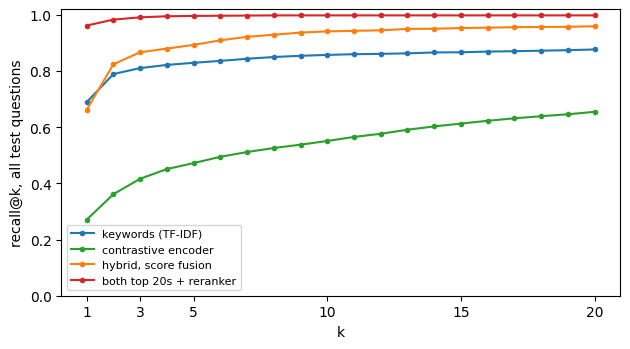


recall@k, all test questions:   k =     1      2      3      5     10     20
  keywords (TF-IDF)            68.9%  78.9%  81.0%  82.9%  85.7%  87.6%
  contrastive encoder          27.1%  36.1%  41.6%  47.2%  55.1%  65.4%
  hybrid, score fusion         66.2%  82.4%  86.6%  89.2%  94.1%  95.9%
  both top 20s + reranker      96.1%  98.2%  99.1%  99.6%  99.8%  99.8%


In [11]:
class WordByWord(layers.Layer):
    """For each question word: best cosine with a passage word, exact match, where the match is, IDF. -> (batch, Lq, 4). No weights."""

    def call(self, qv, pv, q_ids, p_ids, q_idf):
        ops = keras.ops
        unit = lambda x: x / ops.sqrt(ops.sum(x * x, axis=-1, keepdims=True) + 1e-9)
        real = ops.cast(p_ids > 0, "float32")[:, None, :]                        # (batch, 1, Lp): 1 for real words
        sims = ops.matmul(unit(qv), ops.transpose(unit(pv), (0, 2, 1)))           # (batch, Lq, Lp)
        exact = ops.cast(ops.equal(q_ids[:, :, None], p_ids[:, None, :]), "float32") * real
        found = ops.max(exact, axis=2)
        where = 1.0 - ops.cast(ops.argmax(exact, axis=2), "float32") / ops.sum(real, axis=2)
        return ops.stack([ops.max(sims - 2.0 * (1.0 - real), axis=2), found, found * where, q_idf], axis=-1)


class MaskedSum(layers.Layer):
    """(batch, Lq, 1) -> (batch,): add the per-word scores of the real question words."""

    def call(self, per_word, ids):
        return keras.ops.sum(per_word[..., 0] * keras.ops.cast(ids > 0, "float32"), axis=1)


def build_reranker(word_vectors):
    q_ids = layers.Input(shape=(None,), dtype="int32", name="question_ids")
    p_ids = layers.Input(shape=(None,), dtype="int32", name="passage_ids")
    table = layers.Embedding(V, word_vectors.shape[1], trainable=False, name="borrowed_table")
    idf_table = layers.Embedding(V, 1, trainable=False, name="idf")
    q_idf = layers.Reshape((-1,))(idf_table(q_ids))
    features = WordByWord(name="word_by_word")(table(q_ids), table(p_ids), q_ids, p_ids, q_idf)
    per_word = layers.Dense(1, name="score")(layers.Dense(16, activation="relu", name="hidden")(features))
    model = keras.Model([q_ids, p_ids], MaskedSum(name="sum")(per_word, q_ids), name="reranker")
    table.set_weights([word_vectors])
    idf_table.set_weights([(idf * (np.arange(V) > 1))[:, None]])
    return model


reranker = build_reranker(W_enc)
n_trainable = int(sum(np.prod(w.shape) for w in reranker.trainable_weights))
assert n_trainable == (4 * 16 + 16) + (16 + 1) == 97
print(f"reranker: {n_trainable} trainable parameters = (4 x 16 + 16) + (16 + 1); frozen: the encoder's {V} x 64 table and an IDF column")

# hard negatives for the training questions, from the first stage's own top 20
gold_train = np.array([chunk_of_town[q["town"]] for q in train_q])
S_train = zscore(tfidf_queries(train_q, idf) @ X_tfidf.T) + zscore(encoder.predict(Q_train, batch_size=256, verbose=0) @ X_enc.T)
hard = np.array([[j for j in row if j != gold][:20] for row, gold in zip(np.argsort(-S_train, axis=1)[:, :21], gold_train)])


def train_reranker(model, steps=600, batch=32, lr=3e-3):
    opt = keras.optimizers.Adam(lr)

    @tf.function
    def step(q, p):
        with tf.GradientTape() as tape:
            scores = tf.reshape(model([q, p], training=True), (-1, 5))            # column 0 is the right entry
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(
                tf.zeros(tf.shape(scores)[0], tf.int32), scores, from_logits=True))
        opt.apply_gradients(zip(tape.gradient(loss, model.trainable_weights), model.trainable_weights))
        return loss

    history = []
    for _ in range(steps):
        qi = rng.integers(0, len(train_q), batch)
        cand = np.concatenate([gold_train[qi, None], np.stack([rng.choice(hard[n], 4, replace=False) for n in qi])], axis=1)
        history.append(float(step(tf.constant(np.repeat(Q_train[qi], 5, axis=0)), tf.constant(P_all[cand.reshape(-1)]))))
    return history


t0 = time.time()
history = train_reranker(reranker)
print(f"trained 600 steps in {time.time() - t0:.0f} s; loss {np.mean(history[:10]):.2f} at the start (ln 5 = {np.log(5):.2f}), {np.mean(history[-100:]):.3f} at the end")


def rerank(candidates, Q_ids):
    """candidates (questions, n): chunk numbers to score. Returns scores (questions, chunks); chunks not listed get -1e9."""
    n = candidates.shape[1]
    scores = reranker.predict([np.repeat(Q_ids, n, axis=0), P_all[candidates.reshape(-1)]], batch_size=2048, verbose=0).reshape(-1, n)
    out = np.full((len(Q_ids), len(P_all)), -1e9, np.float32)
    np.put_along_axis(out, candidates, scores, axis=1)
    return out


top_of = lambda S, n: np.argsort(-S, axis=1)[:, :n]
t0 = time.time()
S_rerank20 = rerank(top_of(S_hybrid, 20), Q_test)
t_rerank = time.time() - t0
print(f"reranked {len(test_q):,} x 20 candidates in {t_rerank:.1f} s\n")
print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
evaluate("keywords (TF-IDF)", S_tfidf)
evaluate("contrastive encoder", S_enc)
evaluate("hybrid, score fusion", S_hybrid)
ranks_rerank20 = evaluate("hybrid top 20 + reranker", S_rerank20)
print(f"\nceiling: the reranker can only reorder what it is given. The hybrid's recall@20 was {np.mean(ranks_hybrid <= 20):.1%}; "
      f"after reranking, recall@20 is {np.mean(ranks_rerank20 <= 20):.1%}")
for kind in KINDS:
    print(f"  {kind:8s}: hybrid recall@20 {np.mean(ranks_hybrid[kind_of == kind] <= 20):6.1%}   reranked recall@1 {np.mean(ranks_rerank20[kind_of == kind] <= 1):6.1%}")

# widen the net: instead of the fused top 20, hand over each search's own top 20 (up to 40 different chunks)
both_lists = np.concatenate([top_of(S_tfidf, 20), top_of(S_enc, 20)], axis=1)
print(f"\nboth lists' top 20: {np.mean([len(set(row)) for row in both_lists]):.1f} different chunks per question on average")
S_rerank = rerank(both_lists, Q_test)
print(f"{'recall at 1, 3, 10':26s}" + "".join(f" | {kind:8s}{'@1':>6s} {'@3':>6s} {'@10':>6s}" for kind in KINDS + ("all",)))
ranks_rerank = evaluate("both top 20s + reranker", S_rerank)

ks = np.arange(1, 21)
curves = [("keywords (TF-IDF)", ranks_tfidf, "tab:blue"), ("contrastive encoder", ranks_enc, "tab:green"),
          ("hybrid, score fusion", ranks_hybrid, "tab:orange"), ("both top 20s + reranker", ranks_rerank, "tab:red")]
plt.figure(figsize=(6.4, 3.6))
for label, r, colour in curves:
    plt.plot(ks, [np.mean(r <= k) for k in ks], "o-", ms=3, color=colour, label=label)
plt.xticks([1, 3, 5, 10, 15, 20]); plt.ylim(0, 1.02); plt.xlabel("k"); plt.ylabel("recall@k, all test questions")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()
print("\nrecall@k, all test questions:   k = " + "  ".join(f"{k:5d}" for k in (1, 2, 3, 5, 10, 20)))
for label, r, _ in curves:
    print(f"  {label:28s} " + "  ".join(f"{np.mean(r <= k):5.1%}" for k in (1, 2, 3, 5, 10, 20)))

### Why we see this

Ninety-seven trained numbers, on top of word vectors the encoder already had, and recall@1 jumps on the two
kinds of question that were not already perfect.

**Describe questions.** A describe question names four properties, and the right entry is the one that has
**all four**. An averaged vector can only say "this passage is roughly about these things", so an entry
with three of the four is nearly as close as the right one. The reranker checks each question word against
the passage and adds up, so three out of four loses to four out of four. That is the difference between
comparing two summaries and reading the two texts side by side.

**Name questions.** Keyword search could not tell the entry *about* a town from an entry that *mentions* it
as a neighbour. The reranker sees where the match is: at the start of the passage or at the end.

**The ceiling.** The reranker never sees a chunk the first stage did not pass on. Its recall@20 is exactly
the hybrid's, and for describe questions its recall@1 is pressed against that ceiling. The cure for a
ceiling is not a better reranker. It is a wider net: hand over each search's own top 20, and the answers
that only one of them had found come back into play.

The cost: one model call per candidate, where the first stage was one matrix multiply for the whole
collection. And honesty about the toy: these entries were written from templates, so "does this word, or a
near neighbour, occur in the passage?" settles almost every case. Real passages are not so obliging, which
is why real rerankers are transformers and are still not perfect.

---
## Step 12 - Chunk size and overlap

Back to Step 4. Everything so far used entry chunks. Now cut the same pages blindly, at several sizes, and
search each index with the same hybrid (TF-IDF plus the Step 8 encoder; no retraining, no reranker).

Comparing recall@3 across chunk sizes is unfair: three chunks of 320 words are 960 words of prompt, three of
20 are 60. So the cell reports a second measure: **fill a prompt of 130 words** (about three entries) with
the best chunks in order, cutting the last one off where the budget ends. Is the gold sentence in it?

> **Predict:** which window size will be best under the 130-word budget: 10, 20, 40, 80, 160 or 320? What
> goes wrong at each end? And will any blind size beat cutting by entry?

chunking                 chunks | recall@1  recall@3 | in a 130-word prompt: name   code  describe   all | encoder alone, describe @1


windows of 10              2125 |    0.0%     0.1%  |                          0.4%   0.0%     0.0%   0.2% |     0.0%


windows of 20              1077 |    5.6%     6.7%  |                         11.1%   0.0%     0.0%   6.7% |     0.4%


windows of 40               543 |   26.5%    36.4%  |                         50.3%   0.0%    21.0%  36.5% |    18.1%
windows of 80               300 |   39.5%    56.4%  |                         61.5%  50.6%    23.3%  48.9% |    15.4%


windows of 160              180 |   46.8%    65.8%  |                         47.8%  75.6%    16.0%  41.1% |    10.4%
windows of 320              120 |   38.6%    55.2%  |                         18.8%  37.5%     6.7%  17.0% |     7.9%


windows of 40, overlap 10   714 |   24.8%    35.6%  |                         49.7%   0.0%    21.2%  36.2% |    17.5%


windows of 40, overlap 20  1017 |   24.9%    43.1%  |                         60.0%   0.0%    24.6%  43.4% |    22.7%


windows of 80, overlap 40   483 |   44.1%    74.4%  |                         67.0% 100.0%    30.0%  59.2% |    21.7%


by entry                    480 |   66.2%    86.6%  |                         99.2% 100.0%    55.6%  86.2% |    64.6%


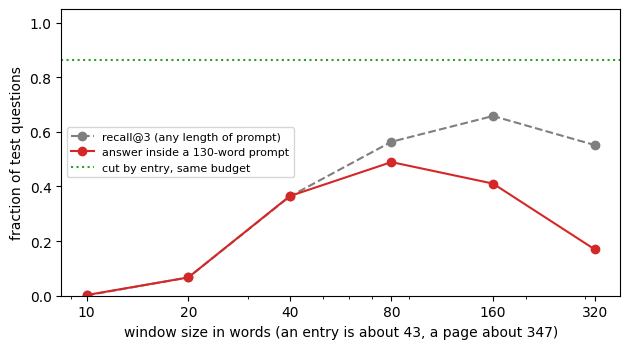

In [12]:
def index_and_search(cs):
    """Hybrid scores of every test question against the chunks cs. Returns scores (questions, chunks)."""
    ctok = [tok(chunk_text(c)) for c in cs]
    X, idf_c = tfidf_index(ctok)
    S_kw = tfidf_queries(test_q, idf_c) @ X.T
    S_vec = encoder.predict(Q_test, batch_size=256, verbose=0) @ encoder.predict(pad(ctok), batch_size=64, verbose=0).T
    return zscore(S_kw) + zscore(S_vec), S_vec


def in_budget(scores, cs, budget=130):
    """For each test question: is the gold sentence inside a prompt of `budget` words filled with the best chunks in order?"""
    top = np.argsort(-scores, axis=1)[:, :30]
    found = np.zeros(len(test_q), bool)
    for n, q in enumerate(test_q):
        left = budget
        for j in top[n]:
            p, a, b = cs[j]
            b = min(b, a + left)                       # the last chunk is cut where the budget ends
            if holds_answer((p, a, b), q):
                found[n] = True
            left -= b - a
            if left <= 0:
                break
    return found


BUDGET = 130
sweep = {}
print(f"{'chunking':24s} {'chunks':>6s} | recall@1  recall@3 | in a {BUDGET}-word prompt: name   code  describe   all | encoder alone, describe @1")
for label, cs in [(f"windows of {s}", chunk_fixed(s)) for s in (10, 20, 40, 80, 160, 320)] + \
                 [("windows of 40, overlap 10", chunk_fixed(40, 10)), ("windows of 40, overlap 20", chunk_fixed(40, 20)),
                  ("windows of 80, overlap 40", chunk_fixed(80, 40)), ("by entry", chunks)]:
    S, S_vec = index_and_search(cs)
    r = gold_ranks(S, test_q, cs)
    fit = in_budget(S, cs, BUDGET)
    sweep[label] = dict(n=len(cs), r1=np.mean(r <= 1), r3=np.mean(r <= 3), fit=fit.mean(),
                        **{k: fit[kind_of == k].mean() for k in KINDS},
                        vec=np.mean(gold_ranks(S_vec, test_q, cs)[kind_of == "describe"] <= 1))
    w = sweep[label]
    print(f"{label:26s} {w['n']:4d} | {w['r1']:7.1%}  {w['r3']:7.1%}  |{'':24s}{w['name']:6.1%} {w['code']:6.1%} {w['describe']:8.1%} {w['fit']:6.1%} | {w['vec']:8.1%}")

sizes = (10, 20, 40, 80, 160, 320)
plt.figure(figsize=(6.4, 3.6))
plt.plot(sizes, [sweep[f"windows of {s}"]["r3"] for s in sizes], "o--", color="tab:gray", label="recall@3 (any length of prompt)")
plt.plot(sizes, [sweep[f"windows of {s}"]["fit"] for s in sizes], "o-", color="tab:red", label=f"answer inside a {BUDGET}-word prompt")
plt.axhline(sweep["by entry"]["fit"], color="tab:green", ls=":", label="cut by entry, same budget")
plt.xscale("log"); plt.xticks(sizes, sizes); plt.ylim(0, 1.05)
plt.xlabel("window size in words (an entry is about 43, a page about 347)"); plt.ylabel("fraction of test questions")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### Why we see this

**Too small.** A 10-word window holds one sentence at best. The sentence that answers `Who founded Cragcott?`
is "It was founded in 1722 by the captain Sunna Varga", and nothing in it says Cragcott. The question finds
the chunk with the name; the answer is next door. Small chunks find precisely and have lost the context
that made them findable. Code questions show the same thing from the other side: the code is in one
sentence and the town's name five sentences earlier, so no window of 40 words or fewer ever holds both.

**Too big.** By recall@3, windows of 160 words look best: of course they do, three of them are 480 words.
Give every size the same 130 words of prompt and the best size drops to 80, with 160 behind it and 320 far
behind: a 320-word chunk does not fit, and the part that fits rarely holds the right sentence. Big chunks
also blur the embedding. The last column is the encoder alone on describe questions, falling steadily as
each vector has to stand for more towns at once. At 320 words even recall@3 has turned down.

**Overlap** repairs part of the damage of a blind cut, and nearly doubles the index. **Cutting on
structure** beats every blind cut here, by a wide margin, because here the structure is clean. The entry is
the unit of meaning; a window size is only a guess at it.

---
## Step 13 - What the index costs, and searching it approximately

Exact search compares the question with every vector. The lab's index is tiny. The arithmetic for a real one:
`chunks x dimensions x 4 bytes` in float32.

When the collection is too large to scan, an **approximate nearest neighbour** index looks at only part
of it. The simplest kind is an inverted file (IVF): cluster the vectors with k-means, remember each cluster's
centre, and at question time scan only the few clusters whose centres are nearest the question.

> **Predict:** with 16 clusters, scanning the nearest 2 looks at about an eighth of the vectors. How often
> will the true nearest chunk be among them: 50%, 75%, 95%?

In [13]:
print(f"this lab      : {X_enc.shape[0]} chunks x {X_enc.shape[1]} x 4 bytes = {X_enc.size * 4 / 1e3:.0f} kB")
print(f"a real index  : 1,000,000 chunks x 768 x 4 bytes = {1e6 * 768 * 4 / 1e9:.2f} GB   ({1e6 * 768 * 4 / 2 ** 30:.2f} GiB)")
print(f"100 million   : {1e8 * 768 * 4 / 1e9:.0f} GB")

Q_enc = encoder.predict(Q_test, batch_size=256, verbose=0)
t0 = time.time()
for _ in range(20):
    exact_top = np.argsort(-(Q_enc @ X_enc.T), axis=1)[:, :10]
print(f"exact search, {len(test_q):,} questions against {len(chunks)} chunks: {1000 * (time.time() - t0) / 20:.1f} ms")

K_CLUSTERS = 16
g = np.random.default_rng(0)
centres = X_enc[g.choice(len(X_enc), K_CLUSTERS, replace=False)].copy()
for _ in range(20):                                       # k-means on unit vectors
    member = np.argmax(X_enc @ centres.T, axis=1)
    for c in range(K_CLUSTERS):
        if np.any(member == c):
            centres[c] = X_enc[member == c].mean(0)
    centres = unit_rows(centres)
member = np.argmax(X_enc @ centres.T, axis=1)
print(f"\n{K_CLUSTERS} clusters, sizes from {np.bincount(member).min()} to {np.bincount(member).max()}")
print("clusters scanned | vectors compared | true nearest chunk found | of the true top 10, found")
ivf = {}
for probes in (1, 2, 4, 8, 16):
    near = np.argsort(-(Q_enc @ centres.T), axis=1)[:, :probes]
    scanned, top1, top10 = [], [], []
    for n in range(len(test_q)):
        allowed = np.where(np.isin(member, near[n]))[0]
        got = allowed[np.argsort(-(X_enc[allowed] @ Q_enc[n]))[:10]]
        scanned.append(len(allowed) / len(X_enc)); top1.append(exact_top[n, 0] in got[:1]); top10.append(len(set(got) & set(exact_top[n])) / 10)
    ivf[probes] = (np.mean(scanned), np.mean(top1), np.mean(top10))
    print(f"{probes:10d}       | {np.mean(scanned):12.1%}     | {np.mean(top1):14.1%}           | {np.mean(top10):10.1%}")

this lab      : 480 chunks x 64 x 4 bytes = 123 kB
a real index  : 1,000,000 chunks x 768 x 4 bytes = 3.07 GB   (2.86 GiB)
100 million   : 307 GB


exact search, 1,600 questions against 480 chunks: 15.3 ms

16 clusters, sizes from 13 to 43
clusters scanned | vectors compared | true nearest chunk found | of the true top 10, found
         1       |         6.4%     |          47.6%           |      34.5%
         2       |        12.5%     |          65.2%           |      51.4%


         4       |        24.6%     |          78.8%           |      69.8%
         8       |        49.5%     |          93.2%           |      88.7%


        16       |       100.0%     |         100.0%           |     100.0%


### Why we see this

Scanning part of the index finds part of what an exact scan finds: here, half the vectors for about 93% of
the true nearest chunks, an eighth for about two thirds. That is the whole trade of approximate search:
recall for speed, with a dial (`probes`) between the two. Note what is being measured: agreement with the
**exact search**, not with the truth. An approximate index can only lose answers the encoder had found.

The trade is poor here because 480 towns that were made to be different do not form natural clusters, and
because 16 clusters is a crude index. Real collections cluster better and real indexes (finer clusters, or a
graph such as HNSW) do far better than this. At 480 vectors there is no reason to use one at all: exact
search took a few milliseconds. At a hundred million vectors there is no alternative.

---
## Step 14 - Build the prompt, and a stand-in for the reader

The retrieval half is done. What a real system does next is put the best passages into a prompt and send it
to a large language model. `build_prompt` writes that prompt. Read it: numbered passages, an instruction to
answer only from them, a way out when they do not hold the answer, and a request to cite.

This lab has no large model. As a stand-in, a second small encoder (the Step 8 architecture again) is trained
on the training towns to pick, inside one passage, the sentence that answers a question. It reads only
passage [1]. It is a pointer, not a writer: it shows what would be handed to the model, and lets us score
the whole chain.

> **Predict:** if the right passage is not passage [1], how often will the reader's answer be right? And when it is
> passage [1]?

In [14]:
def build_prompt(question, passages):
    lines = ["Answer the question using only the numbered passages below.",
             "After each statement, cite the passage it came from, like [2].",
             "If the passages do not contain the answer, reply: I do not know.", ""]
    lines += [f"[{n + 1}] {text}" for n, text in enumerate(passages)]
    return "\n".join(lines + ["", f"Question: {question}", "Answer:"])


n = int(np.where((kind_of == "describe") & (ranks_rerank == 1))[0][0])
top3 = np.argsort(-S_rerank[n])[:3]
print(build_prompt(test_q[n]["text"], [chunk_text(chunks[j]) for j in top3]))
print("-" * 100)

# the stand-in reader: a Step 8 encoder trained to pick, among the sentences of ONE entry, the one that answers
sent_tok = {(i, k): tok(s) for i in range(N_TOWNS) for k, s in enumerate(entries[i])}
S_LEN = max(len(t) for t in sent_tok.values())
SENT = np.zeros((N_TOWNS, 6, S_LEN), np.int32)             # every entry as up to 6 sentences of ids
for i in range(N_TOWNS):
    SENT[i, :len(entries[i])] = pad([sent_tok[(i, k)] for k in range(len(entries[i]))], S_LEN)
train_town = np.array([q["town"] for q in train_q])
train_sent = np.array([q["sent"] for q in train_q])
test_town = np.array([q["town"] for q in test_q])
test_sent = np.array([q["sent"] for q in test_q])

reader = build_encoder(name="reader")
reader_opt = keras.optimizers.Adam(3e-3)


def sentence_scores(q, s):
    """Cosine of each question (B, Lq) with each of its entry's sentences (B, 6, S_LEN). Missing sentences get -1e9."""
    sv = tf.reshape(reader(tf.reshape(s, (-1, S_LEN))), (-1, 6, 64))
    return tf.einsum("bd,bkd->bk", reader(q), sv) - 1e9 * tf.cast(tf.reduce_max(s, axis=2) == 0, tf.float32)


@tf.function
def reader_step(q, s, y):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(y, sentence_scores(q, s) / 0.05, from_logits=True))
    reader_opt.apply_gradients(zip(tape.gradient(loss, reader.trainable_weights), reader.trainable_weights))
    return loss


t0 = time.time()
for _ in range(300):
    qi = rng.integers(0, len(train_q), BATCH)
    loss = reader_step(tf.constant(Q_train[qi]), tf.constant(SENT[train_town[qi]]), tf.constant(train_sent[qi]))
print(f"reader trained 300 steps in {time.time() - t0:.0f} s; last loss {float(loss):.4f}")


def read(Q_ids, town_of_passage):
    """For each question, the number of the sentence the reader picks in the entry of the given town."""
    return np.concatenate([np.argmax(sentence_scores(tf.constant(Q_ids[a:a + 400]), tf.constant(SENT[town_of_passage[a:a + 400]])).numpy(), axis=1)
                           for a in range(0, len(Q_ids), 400)])


town_of_chunk = np.array([int(i) for i in order])
first = town_of_chunk[np.argmax(S_rerank, axis=1)]         # the town of passage [1], for every test question
picked = read(Q_test, first)
correct = (first == test_town) & (picked == test_sent)
given_right = read(Q_test, test_town) == test_sent

print(f"\nQuestion : {test_q[n]['text']}")
print(f"Extracted: {entries[first[n]][picked[n]]} [1]")
print(f"\nreader alone, handed the right passage: picks the gold sentence for {given_right.mean():.1%} of test questions")
print("\nwhere the gold passage was  | questions | extracted sentence is the gold one")
for label, sel in (("passage [1]", ranks_rerank == 1), ("passage [2] or [3]", (ranks_rerank > 1) & (ranks_rerank <= 3)), ("not in the prompt", ranks_rerank > 3)):
    print(f"  {label:25s} | {sel.sum():6d}    | {correct[sel].mean() if sel.any() else 0:8.1%}")
print(f"  {'all test questions':25s} | {len(test_q):6d}    | {correct.mean():8.1%}")
print("\nthe same reader behind each retriever (extracted sentence is the gold one):")
for label, S in (("keywords (TF-IDF)", S_tfidf), ("contrastive encoder", S_enc), ("hybrid, score fusion", S_hybrid), ("both top 20s + reranker", S_rerank)):
    town1 = town_of_chunk[np.argmax(S, axis=1)]
    ok = (town1 == test_town) & (read(Q_test, town1) == test_sent)
    print(f"  {label:26s} {ok.mean():6.1%}    (its recall@1 was {results[label]['all'][0]:.1%})")

Answer the question using only the numbered passages below.
After each statement, cite the passage it came from, like [2].
If the passages do not contain the answer, reply: I do not know.

[1] Cragcott is a settlement in a land of thickets and groves. It was founded in 1722 by the captain Sunna Varga. It is famous for its inks and its paper. Every summer it holds a blaze. Its registry code is JM-7015. The nearest settlement is Rookholm.
[2] Stanfield is a village in a land of groves and woods. It was established in 1418 by the captain Jorun Kessel. It is famous for its clay and its tiles. Every june it holds a blaze. Its registry code is HP-2802.
[3] Garthdale is a village in a land of woods and forests. It was founded in 1416 by the widow Jorun Voss. It is famous for its ovens and its loaves. Every june it holds a blaze. Its registry code is HE-4006.

Question: Which place among the woods is noted for its inks and has a blaze each july?
Answer:
----------------------------------------

reader trained 300 steps in 1 s; last loss 0.0002

Question : Which place among the woods is noted for its inks and has a blaze each july?
Extracted: Cragcott is a settlement in a land of thickets and groves. [1]

reader alone, handed the right passage: picks the gold sentence for 100.0% of test questions

where the gold passage was  | questions | extracted sentence is the gold one
  passage [1]               |   1538    |   100.0%
  passage [2] or [3]        |     47    |     0.0%
  not in the prompt         |     15    |     0.0%
  all test questions        |   1600    |    96.1%

the same reader behind each retriever (extracted sentence is the gold one):
  keywords (TF-IDF)           68.9%    (its recall@1 was 68.9%)
  contrastive encoder         27.1%    (its recall@1 was 27.1%)


  hybrid, score fusion        66.2%    (its recall@1 was 66.2%)
  both top 20s + reranker     96.1%    (its recall@1 was 96.1%)


### Why we see this

Handed the right passage, the reader is nearly always right: picking the sentence is the easy part here. So
the end-to-end score is, almost exactly, **recall@1 of the retrieval**. When the gold passage is not first,
the stand-in reader is always wrong. It cannot be otherwise: the answer is not in what it reads.

A large model in the reader's place changes one row of that table and not the other. It reads all the
numbered passages, so an answer in passage [2] or [3] is still within reach. An answer that is not in the
prompt is not within reach of any reader. It will either say it does not know, or write something fluent
from its weights. This lab cannot show you which.

---
## Step 15 - The way out: "I do not know"

A search **always** returns a top chunk, even when the collection holds nothing on the subject. So ask 240
questions that have no answer here: 120 about towns that do not exist (the names kept back in Step 2), and
120 that describe a combination of land, trade, event and season that no town has.

The only signal available is the **score** of the best chunk. Set a threshold: below it, the system says
"I do not know" and no prompt is built.

> **Predict:** which kind of unanswerable question is easier to catch by its score: an unknown name, or an
> unknown combination of perfectly ordinary words?

Who begun Thornness?   best score: 14.44
Which place among the atolls is noted for its saltworks and has a bazaar each october?   best score: 79.21


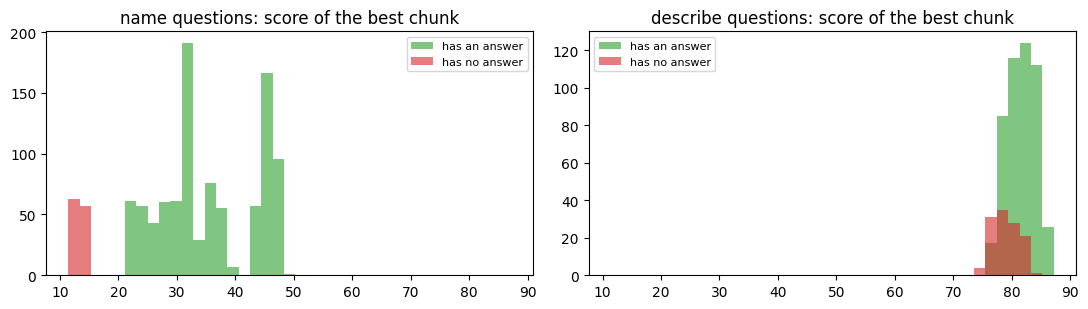


threshold set so that it wrongly refuses 5% of the answerable questions of that kind:
  name    : threshold  22.90 -> refuses 100.0% of the unanswerable ones
  describe: threshold  77.78 -> refuses  32.5% of the unanswerable ones
  one threshold for everything (23.67): refuses 100.0% of unknown names, 0.0% of unknown combinations

total runtime: 23 s


In [15]:
no_answer = [dict(kind="name", text=f"Who {pick(FOUND_Q)} {name}?") for name in spare_names] + \
            [dict(kind="describe", text=f"Which place among the {pick(LAND[a])} is {pick(KNOWN_Q)} for its {pick(TRADE[b])} "
                                        f"and has a {pick(EVENT[d])} each {pick(SEASON[c])}?") for a, b, c, d in spare_combos[:120]]
na_tok = [tok(q["text"]) for q in no_answer]
Q_na = pad(na_tok, Q_test.shape[1])
best_na = rerank(np.concatenate([top_of(tfidf_queries(no_answer, idf) @ X_tfidf.T, 20),
                                  top_of(encoder.predict(Q_na, batch_size=256, verbose=0) @ X_enc.T, 20)], axis=1), Q_na).max(axis=1)
best_ok = S_rerank.max(axis=1)
na_kind = np.array([q["kind"] for q in no_answer])
print(no_answer[0]["text"], "  best score:", round(float(best_na[0]), 2))
print(no_answer[120]["text"], "  best score:", round(float(best_na[120]), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, kind in zip(axes, ("name", "describe")):
    lo, hi = min(best_na.min(), best_ok.min()), max(best_na.max(), best_ok.max())
    ax.hist(best_ok[kind_of == kind], bins=np.linspace(lo, hi, 40), color="tab:green", alpha=0.6, label="has an answer")
    ax.hist(best_na[na_kind == kind], bins=np.linspace(lo, hi, 40), color="tab:red", alpha=0.6, label="has no answer")
    ax.set_title(f"{kind} questions: score of the best chunk"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("\nthreshold set so that it wrongly refuses 5% of the answerable questions of that kind:")
for kind in ("name", "describe"):
    threshold = np.quantile(best_ok[kind_of == kind], 0.05)
    print(f"  {kind:8s}: threshold {threshold:6.2f} -> refuses {np.mean(best_na[na_kind == kind] < threshold):6.1%} of the unanswerable ones")
threshold = np.quantile(best_ok, 0.05)
print(f"  one threshold for everything ({threshold:.2f}): refuses {np.mean(best_na[na_kind == 'name'] < threshold):.1%} of unknown names, "
      f"{np.mean(best_na[na_kind == 'describe'] < threshold):.1%} of unknown combinations")
print(f"\ntotal runtime: {time.time() - t_start:.0f} s")

### Why we see this

An unknown name is easy to refuse: the one word that mattered matches nothing, and the best score is far
below anything an answerable question produces. An unknown **combination** is hard. Some town really is
among the atolls, another really is known for its saltworks, and the best chunk matches most of the question.
Its score looks like the score of a slightly unlucky answerable question. No threshold separates the two cleanly.

Two cautions. These thresholds were set on the same test questions they are judged on, which flatters them:
set yours on held-out questions. And a score threshold is only the first way out. The second is the line in
the prompt that tells the model to say so when the passages do not hold the answer, and whether a model obeys
that line has to be measured too (Chapter 44).

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 8: `stddev=0.01` in `build_encoder` (words start tiny, not length 1) | The encoder's recall on name and code questions? On describe questions? | |
| 2 | Step 7: average with IDF weights (`table[ids] * idf[ids, None]`) | Does weighting rescue averaged word vectors? | |
| 3 | Step 10: `S_hybrid = zscore(S_tfidf) + 0.5 * zscore(S_enc)`, then `2.0 *` | Which kinds gain and which lose as the encoder's weight grows? | |
| 4 | Step 10: `rrf(..., k=5)` | Does a smaller constant rescue rank fusion at rank 1? At rank 10? | |
| 5 | Step 11: `rerank(top_of(S_hybrid, 5), Q_test)`, then `50` | recall@1 and the time taken, at each | |
| 6 | Step 11: `build_reranker(W_word)`: borrow the Step 7 skip-gram vectors instead | Which kinds of question still work? Which collapse? | |
| 7 | Step 12: `BUDGET = 390` | Which window size is best now? Does "too big" move? | |
| 8 | Step 2: `rng.random() < 1.0` for the neighbour (every entry names another town) | Keyword recall@1 on name questions? recall@3? | |

---
## Exercises

1. **BM25.** Replace the TF-IDF score with BM25: for each question word found in a chunk, add
   `idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * length / average length))` with `k1 = 1.2`, `b = 0.75`.
   Compare recall on name questions at rank 1. What does the length term do to the short neighbour entries?
2. **Give a chunk its context.** In Step 12, prepend the name of the town the chunk's first word belongs to
   (`entry_span` tells you) to every 20-word window before indexing it. Measure the 130-word-budget recall
   again. This is the idea behind adding a title or a summary line to every chunk.
3. **Subword names.** The encoder is blind to names it never trained on. Add, for every word, the vectors of
   its character trigrams (hash them into 2,000 buckets) to the word's own vector. Do name questions improve?
   What do `Marrowwick` and `Marrowford` now have in common, and is that good?
4. **MRR by hand.** For five test questions print the rank of the gold chunk under keywords, encoder and
   hybrid, and compute each method's MRR on those five by hand. Check against `1 / ranks`.
5. **Stale index.** Change the founder of ten test towns in `entries` and rebuild `pages` **without**
   rebuilding `X_tfidf` and `X_enc`. Run Step 14 for those towns. What does the system answer, and what in
   its output would tell a user that something is wrong?
6. **A second hop.** Write questions of the form "Who founded the nearest town to X?". The answer needs two
   retrievals. Measure single-shot recall, then implement the two steps and measure again.

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| The two phases | index: load, clean, chunk, embed, store. answer: embed the question, search, rerank, build the prompt, generate, cite |
| A chunk holds the answer | the whole gold sentence lies inside it |
| recall@k | fraction of questions with an answer-holding chunk in the top k |
| MRR | mean of 1 / rank of the first answer-holding chunk |
| TF-IDF | count x ln((1 + N) / (1 + df)) + 1, rows scaled to length 1; search = one matrix multiply |
| Keywords | win on names, codes and rare strings; blind to a different word for the same thing |
| Averaged word vectors | know that words are related; a poor retriever: every word gets one vote |
| Contrastive encoder | same architecture, trained on question-passage pairs with in-batch negatives; wins on paraphrase |
| Its weakness | strings it never trained on: names, codes |
| Hybrid | add z-scored scores, or reciprocal ranks 1 / (60 + rank); rank fusion ignores how sure each list is |
| Reranker | reads question and passage together, on the top 20 only; cannot recover what the first stage missed |
| Chunks too small | the answer loses the words that made it findable |
| Chunks too big | blurred vectors, and the prompt budget is spent on text that is not the answer |
| Index storage | chunks x dimensions x 4 bytes: one million x 768 = 3.07 GB |
| Approximate search | scan a few clusters: a little recall for a lot of speed |
| The prompt | numbered passages, answer only from them, cite, and an explicit "I do not know" |
| End to end | the answer cannot be better than the search: measure the two halves separately |